# 06 · Design questions

$$R_t = \frac{\text{irrigation months without deficit}}{\text{irrigation months}}, \qquad R_v = \frac{\sum Q_s}{\sum D}$$

a) **How high?** smallest $h_{max}$ (and $V_{max}$) with $R_t \ge R^*$, refined model $A(h)$.
b) **How reliable?** $R_t$ and $R_v$ for the given demand and $h_{max}$.

In [1]:
%load_ext autoreload
%autoreload 2                  
import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

In [2]:
from epss.eflows import eflow_targets
from epss.metrics import reliability_time, reliability_volume, required_hmax
from epss.reservoir import Reservoir

cat = pd.read_csv(PROC / "catchment.csv", index_col=0, parse_dates=True)
cat = cat.dropna(subset=["inflow", "pet"])
inflow, evap = cat.inflow, cat.pet
hv = pd.read_csv(DATA / "hv_curve.csv")
months = case["irrigation_months"]


def demand_series(index, d):
    return pd.Series(np.where(index.month.isin(months), d, 0.0), index=index)


demand = demand_series(inflow.index, case["demand_hm3_per_month"])
eflow = eflow_targets(inflow, case["eflow_fraction"])
hmin, target = case["hmin_m"], case["target_reliability"]

## b) How reliable?

In [6]:
# TODO: Simulate the reservoir with the given hmax and the refined model A(h) (no fixed area);
#       compute Rt and Rv.
# In: hv, case, hmin, inflow, evap, demand, eflow
# Out: sim (DataFrame), rt, rv (floats)
res = Reservoir(hv, case["hmax_m"], hmin)
sim = res.simulate(inflow, evap, demand, eflow)

rt = reliability_time(sim)
rv = reliability_volume(sim)
print(f"hmax = {case['hmax_m']} m: Rt = {rt:.3f}, Rv = {rv:.3f}")

hmax = 5.0 m: Rt = 0.656, Rv = 0.669


## a) How high?

Required hmax = 7.33 m, Vmax = 0.656 hm³


Text(0, 0.5, 'Reliability (-)')

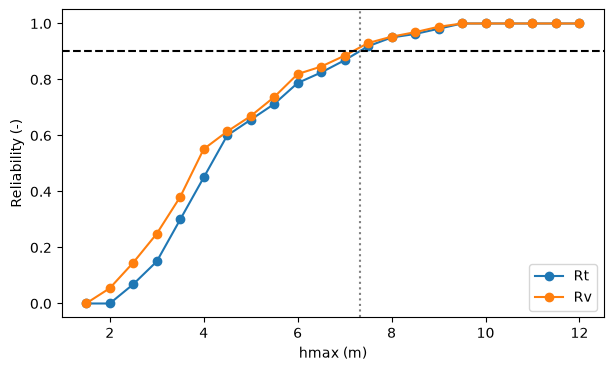

In [10]:
hs = np.arange(1.5, hv.h_m.max() + 0.01, 0.5)
curve = pd.DataFrame([(h, reliability_time(s), reliability_volume(s))
                      for h in hs for s in [Reservoir(hv, h, hmin).simulate(inflow, evap, demand, eflow)]],
                     columns=["hmax", "Rt", "Rv"]).set_index("hmax")
# TODO: Smallest hmax with Rt >= R* (required_hmax) and the corresponding Vmax from the h-V curve.
# In: hv, inflow, evap, demand, eflow, target, hmin
# Out: h_star (m), v_star (hm³)
h_star = required_hmax(hv, inflow, evap, demand, eflow, target, hmin)
v_star = np.interp(h_star, hv["h_m"], hv["v_hm3"])
print(f"Required hmax = {h_star:.2f} m, Vmax = {v_star:.3f} hm³")
ax = curve.plot(marker="o", figsize=(7, 4))
ax.axhline(target, c="k", ls="--"); ax.axvline(h_star, c="grey", ls=":")
ax.set_xlabel("hmax (m)"); ax.set_ylabel("Reliability (-)")

Sensitivity to the demand (±25 %).

In [11]:
rows = []
for f in [0.75, 1.0, 1.25]:
    d = demand_series(inflow.index, f * case["demand_hm3_per_month"])
    s = Reservoir(hv, case["hmax_m"], hmin).simulate(inflow, evap, d, eflow)
    rows.append((f, reliability_time(s), reliability_volume(s), required_hmax(hv, inflow, evap, d, eflow, target, hmin)))
pd.DataFrame(rows, columns=["demand factor", "Rt", "Rv", "required hmax (m)"]).round(3)

,demand factor,Rt,Rv,required hmax (m)
0,0.75,0.712,0.718,6.865
1,1.00,0.656,0.669,7.333
2,1.25,0.600,0.639,7.741


In [12]:
test = Reservoir(hv, 6.76, hmin).simulate(inflow, evap, demand, eflow)

print("Rt a 6.76 m:", reliability_time(test))
print("Altura necessária:", required_hmax(hv, inflow, evap, demand, eflow, target, hmin))

Rt a 6.76 m: 0.85625
Altura necessária: 7.33251953125


## Optional: climate change (+2 °C)
T, Tmax and Tmin are increased by 2 °C (P unchanged); repeat PET → T–M → inflow → design.

In [13]:
from epss.pet import pet_monthly
from epss.soil import thornthwaite_mather

clim = pd.read_csv(PROC / "climate.csv", index_col=0, parse_dates=True)
# TODO: Climate change: T, Tmax and Tmin + 2 °C -> PET -> Thornthwaite-Mather -> inflow -> e-flow
#       targets -> simulation at the given hmax with A(h).
# In: clim, case, hv, hmin, demand
# Out: pet_cc, tm_cc, inflow_cc, eflow_cc, sim_cc
clim_cc = clim.loc[inflow.index].copy()

pet_cc = pet_monthly(
    clim_cc["t_c"] + 2,
    clim_cc["tmax_c"] + 2,
    clim_cc["tmin_c"] + 2,
    case["latitude_deg"]
)

tm_cc = thornthwaite_mather(
    clim_cc["p_mm"],
    pet_cc,
    case["smax_mm"],
    s0=case["smax_mm"]
)

inflow_cc = tm_cc["runoff"] * case["catchment_area_km2"] / 1000

eflow_cc = eflow_targets(inflow_cc, case["eflow_fraction"])

sim_cc = Reservoir(hv, case["hmax_m"], hmin).simulate(
    inflow_cc, pet_cc, demand, eflow_cc
)
yearly = lambda s: s.groupby(s.index.year).sum().mean()
pd.DataFrame({
    "present": [yearly(evap), yearly(inflow), rt, rv, h_star],
    "+2 °C": [yearly(pet_cc), yearly(inflow_cc), reliability_time(sim_cc), reliability_volume(sim_cc),
              required_hmax(hv, inflow_cc, pet_cc, demand, eflow_cc, target, hmin)],
}, index=["PET (mm/yr)", "Qin (hm³/yr)", "Rt", "Rv", "required hmax (m)"]).round(3)

,present,+2 °C
PET (mm/yr),1215.644,1281.461
Qin (hm³/yr),3.977,3.657
Rt,0.656,0.594
Rv,0.669,0.609
required hmax (m),7.333,7.886


**Answer.**

An increase of 2 °C leads to higher potential evapotranspiration, from 1215.6 to 1281.5 mm/year, and reduces the annual inflow from 3.977 to 3.657 hm³/year.

As a result, the reservoir has less water available for irrigation. Time reliability decreases from 65.6% to 59.4%, while volumetric reliability decreases from 66.9% to 60.9%.

To achieve the target reliability of 90%, the required reservoir height increases from 7.33 m to 7.89 m.

These results show that higher temperatures can reduce water availability and increase the storage capacity needed to meet irrigation demand.